<a href="https://colab.research.google.com/github/eminealoui/INVESTIA/blob/main/D01_heart_comprehensive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modèle de notebook — à copier

1. **Fichier → Enregistrer une copie dans Drive**, puis renomme (ex. `D03_heart_kaggle.ipynb` ou `T_m2_shap.ipynb`).
2. 🔑 à gauche : secret `GITHUB_TOKEN` + accès activé.
3. Mets ton code dans **CONFIG**, lance **CONFIG** puis **SETUP**.
4. Travaille dans les cellules du milieu (suis `docs/membres/PROCESS_DATASET.md` et ton fichier `docs/taches/Mx_ETAPES.md`).
5. Finis par **SAUVEGARDE** + *Fichier → Enregistrer une copie dans GitHub* (ta branche).

Règles : uniquement tes fichiers · uniquement ta branche · jamais `data/raw/`.

In [1]:
# ===== CONFIG : mets ton code membre (m1, m2, m3, m4, m5, m6) =====
MEMBRE = "m1"

In [2]:
# ===== SETUP : à relancer au début de CHAQUE séance =====
import os
from google.colab import userdata
assert MEMBRE in ["m1","m2","m3","m4","m5","m6"], "Mets ton code membre dans la cellule CONFIG"
token = userdata.get("GITHUB_TOKEN")
REPO = "/content/ensemble-disease-prediction"
if not os.path.exists(REPO):
    !git clone -q https://{token}@github.com/eminealoui/ensemble-disease-prediction.git {REPO}
%cd {REPO}
!git config user.name "{MEMBRE}" && git config user.email "{MEMBRE}@projet.local" && git config pull.rebase false
!git fetch -q origin
!git checkout -q {MEMBRE} 2>/dev/null || git checkout -q -b {MEMBRE}
!git pull -q --no-edit origin {MEMBRE} 2>/dev/null || true
!git pull -q --no-edit origin main
!git push -q -u origin {MEMBRE}
!pip install -q catboost scikit-posthocs shap kagglehub ucimlrepo
import warnings; warnings.filterwarnings("ignore")
!git branch --show-current

/content/ensemble-disease-prediction
m1


## Ton travail
(suis ton `docs/taches/Mx_ETAPES.md`)

In [3]:
DS = "D01"          # ← ton dataset (voir TASKS.md)
from src.data import available, REGISTRY
print("Datasets déjà présents :", available())
print(REGISTRY[DS])

Datasets déjà présents : ['D01', 'D02', 'D03', 'D04', 'D06', 'D07', 'D08', 'D09', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'D16']
{'name': 'Heart Disease Comprehensive', 'category': 'heart', 'owner': 'm1', 'file': 'd01_heart_comprehensive.csv', 'source': ('kaggle', 'sid321axn/heart-statlog-cleveland-hungary-final', 'heart_statlog_cleveland_hungary_final.csv'), 'target': 'target', 'positive': 1, 'zero_as_nan': ['cholesterol', 'resting bp s', 'ST slope'], 'categorical': ['chest pain type', 'resting ecg', 'ST slope'], 'verified': True}


In [4]:
# ===== D01 — Vérification du chargement (PROCESS_DATASET, point 3) =====
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
from src.data import load_dataset, path, REGISTRY
pd.set_option("display.max_columns", 50)

raw = pd.read_csv(path(DS))
X, y = load_dataset(DS)

print("Configuration utilisée :")
for k, v in REGISTRY[DS].items():
    print(f"  {k:12s} = {v}")

print("\nFichier brut :", raw.shape)
print("Colonnes :", list(raw.columns))
print("Après chargement : X", X.shape, "| y", y.value_counts().sort_index().to_dict(), "(0 = sain, 1 = malade)")

attendu = {"lignes": 1190, "malades": 629, "sains": 561}
obtenu  = {"lignes": len(y), "malades": int((y == 1).sum()), "sains": int((y == 0).sum())}
print("\nAttendu (article) :", attendu)
print("Obtenu            :", obtenu, "→", "✔ conforme" if attendu == obtenu else "⚠ ÉCART à expliquer")
display(raw.head())

Configuration utilisée :
  name         = Heart Disease Comprehensive
  category     = heart
  owner        = m1
  file         = d01_heart_comprehensive.csv
  source       = ('kaggle', 'sid321axn/heart-statlog-cleveland-hungary-final', 'heart_statlog_cleveland_hungary_final.csv')
  target       = target
  positive     = 1
  zero_as_nan  = ['cholesterol', 'resting bp s']
  categorical  = ['chest pain type', 'resting ecg', 'ST slope']
  verified     = True

Fichier brut : (1190, 12)
Colonnes : ['age', 'sex', 'chest pain type', 'resting bp s', 'cholesterol', 'fasting blood sugar', 'resting ecg', 'max heart rate', 'exercise angina', 'oldpeak', 'ST slope', 'target']
Après chargement : X (1190, 11) | y {0: 561, 1: 629} (0 = sain, 1 = malade)

Attendu (article) : {'lignes': 1190, 'malades': 629, 'sains': 561}
Obtenu            : {'lignes': 1190, 'malades': 629, 'sains': 561} → ✔ conforme


,age,sex,chest pain type,resting bp s,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,40,1,2,140,289,0,0,172,0,0.0,1,0
1,49,0,3,160,180,0,0,156,0,1.0,2,1
2,37,1,2,130,283,0,1,98,0,0.0,1,0
3,48,0,4,138,214,0,0,108,1,1.5,2,1
4,54,1,3,150,195,0,0,122,0,0.0,1,0


In [5]:
# ===== EDA D01 — Section 1 : Aperçu =====
import os
os.makedirs("results/figures", exist_ok=True); os.makedirs("results/tables", exist_ok=True)
assert len(y) == 1190 and (y == 1).sum() == 629, "Effectifs différents de l'article : arrête-toi et envoie la sortie"

DESC = {
    "age": ("Âge", "années"),
    "sex": ("Sexe (1 = homme, 0 = femme)", "-"),
    "chest pain type": ("Douleur thoracique (1 typique, 2 atypique, 3 non angineuse, 4 asymptomatique)", "-"),
    "resting bp s": ("Pression artérielle systolique au repos", "mm Hg"),
    "cholesterol": ("Cholestérol sérique", "mg/dl"),
    "fasting blood sugar": ("Glycémie à jeun > 120 mg/dl (1 = oui)", "-"),
    "resting ecg": ("ECG au repos (0 normal, 1 anomalie ST-T, 2 hypertrophie VG)", "-"),
    "max heart rate": ("Fréquence cardiaque maximale", "bpm"),
    "exercise angina": ("Angine à l'effort (1 = oui)", "-"),
    "oldpeak": ("Dépression du segment ST", "mm"),
    "ST slope": ("Pente du segment ST (1 montante, 2 plate, 3 descendante)", "-"),
    "target": ("CIBLE (1 = malade, 0 = sain)", "-"),
}
NUM = ["age", "resting bp s", "cholesterol", "max heart rate", "oldpeak"]
BIN = ["sex", "fasting blood sugar", "exercise angina"]
CAT = ["chest pain type", "resting ecg", "ST slope"]
TYPE = {**{c: "numérique" for c in NUM}, **{c: "binaire" for c in BIN},
        **{c: "catégorielle" for c in CAT}, "target": "cible"}

apercu = pd.DataFrame({
    "type_pandas": raw.dtypes.astype(str), "type_retenu": pd.Series(TYPE),
    "nb_valeurs_distinctes": raw.nunique(), "manquants_NaN": raw.isna().sum(),
    "nb_zéros": (raw == 0).sum(), "min": raw.min(), "max": raw.max(),
    "description": pd.Series({k: v[0] for k, v in DESC.items()}),
    "unité": pd.Series({k: v[1] for k, v in DESC.items()}),
}).loc[raw.columns]
display(apercu)
apercu.to_csv("results/tables/D01_apercu_variables.csv")

# Valeurs impossibles (0 n'a de sens que pour oldpeak et les variables binaires/catégorielles codées 0)
print("=== Zéros médicalement impossibles ===")
for c in ["age", "resting bp s", "cholesterol", "max heart rate"]:
    n = int((raw[c] == 0).sum())
    if n:
        taux = raw.loc[raw[c] == 0, "target"].mean()
        print(f"  {c:15s}: {n:3d} zéros | {taux:.0%} de malades parmi eux (contre {raw['target'].mean():.0%} au global)")
    else:
        print(f"  {c:15s}: 0")
print("Modalité inattendue 'ST slope' = 0 :", int((raw["ST slope"] == 0).sum()), "ligne(s)")
print("Modalités :", {c: raw[c].value_counts().sort_index().to_dict() for c in CAT})

,type_pandas,type_retenu,nb_valeurs_distinctes,manquants_NaN,nb_zéros,min,max,description,unité
age,int64,numérique,50,0,0,28.0,77.0,Âge,années
sex,int64,binaire,2,0,281,0.0,1.0,"Sexe (1 = homme, 0 = femme)",-
chest pain type,int64,catégorielle,4,0,0,1.0,4.0,"Douleur thoracique (1 typique, 2 atypique, 3 n...",-
resting bp s,int64,numérique,67,0,1,0.0,200.0,Pression artérielle systolique au repos,mm Hg
cholesterol,int64,numérique,222,0,172,0.0,603.0,Cholestérol sérique,mg/dl
fasting blood sugar,int64,binaire,2,0,936,0.0,1.0,Glycémie à jeun > 120 mg/dl (1 = oui),-
resting ecg,int64,catégorielle,3,0,684,0.0,2.0,"ECG au repos (0 normal, 1 anomalie ST-T, 2 hyp...",-
max heart rate,int64,numérique,119,0,0,60.0,202.0,Fréquence cardiaque maximale,bpm
exercise angina,int64,binaire,2,0,729,0.0,1.0,Angine à l'effort (1 = oui),-
oldpeak,float64,numérique,53,0,455,-2.6,6.2,Dépression du segment ST,mm


=== Zéros médicalement impossibles ===
  age            : 0
  resting bp s   :   1 zéros | 100% de malades parmi eux (contre 53% au global)
  cholesterol    : 172 zéros | 88% de malades parmi eux (contre 53% au global)
  max heart rate : 0
Modalité inattendue 'ST slope' = 0 : 1 ligne(s)
Modalités : {'chest pain type': {1: 66, 2: 216, 3: 283, 4: 625}, 'resting ecg': {0: 684, 1: 181, 2: 325}, 'ST slope': {0: 1, 1: 526, 2: 582, 3: 81}}


=== Doublons ===
Lignes en double (copie exacte d'une ligne précédente) : 272
Lignes concernées par un doublon (originaux + copies)  : 544
Profils identiques avec des cibles différentes (conflits) : 0
Position des copies dans le fichier : lignes 163 à 1160
Copies situées dans les 270 dernières lignes (bloc Statlog ?) : 237


,lignes,malades,sains,% malades,doublons,cholestérol = 0,cholestérol NaN,cholestérol moyen
version,,,,,,,,
1. Brut (article),1190,629,561,52.9,272,172,0,210.4
2. Sans doublons,918,508,410,55.3,0,172,0,198.8
3. Sans doublons + 0 → NaN,918,508,410,55.3,0,0,172,244.6


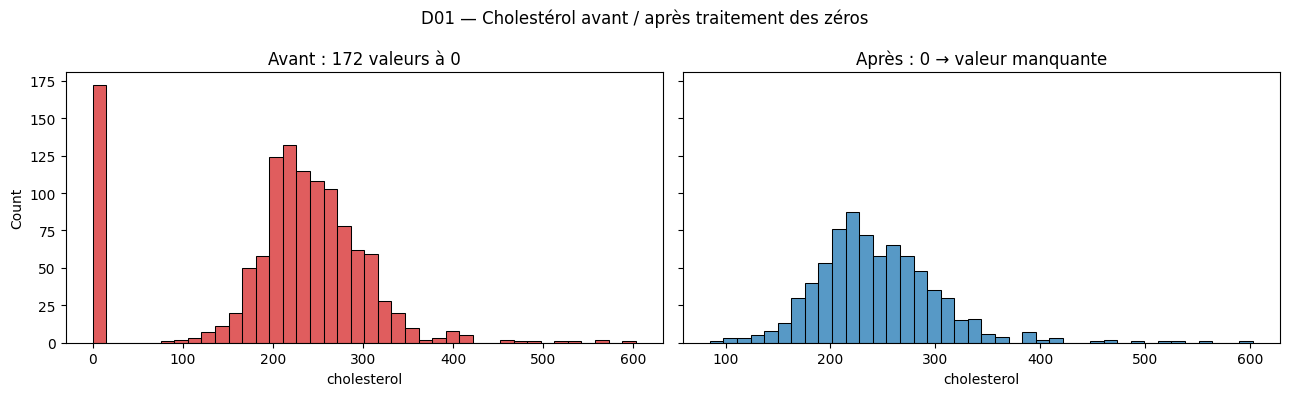

In [6]:
# ===== EDA D01 — Section 2 : Doublons + comparaison avant / après nettoyage =====
dup_all  = raw.duplicated(keep="first")
dup_feat = raw.drop(columns="target").duplicated(keep=False)
conflits = raw[dup_feat].groupby(list(raw.columns.drop("target")))["target"].nunique().gt(1).sum()

print("=== Doublons ===")
print("Lignes en double (copie exacte d'une ligne précédente) :", int(dup_all.sum()))
print("Lignes concernées par un doublon (originaux + copies)  :", int(raw.duplicated(keep=False).sum()))
print("Profils identiques avec des cibles différentes (conflits) :", int(conflits))
print("Position des copies dans le fichier : lignes", dup_all[dup_all].index.min(), "à", dup_all[dup_all].index.max())
print("Copies situées dans les 270 dernières lignes (bloc Statlog ?) :", int(dup_all.iloc[-270:].sum()))

sans_dup = raw.drop_duplicates()
apres = sans_dup.copy()
apres[["cholesterol", "resting bp s"]] = apres[["cholesterol", "resting bp s"]].replace(0, np.nan)

def bilan(d, nom):
    return {"version": nom, "lignes": len(d), "malades": int((d.target == 1).sum()), "sains": int((d.target == 0).sum()),
            "% malades": round(100 * d.target.mean(), 1), "doublons": int(d.duplicated().sum()),
            "cholestérol = 0": int((d.cholesterol == 0).sum()), "cholestérol NaN": int(d.cholesterol.isna().sum()),
            "cholestérol moyen": round(d.cholesterol.mean(), 1)}
comp = pd.DataFrame([bilan(raw, "1. Brut (article)"), bilan(sans_dup, "2. Sans doublons"),
                     bilan(apres, "3. Sans doublons + 0 → NaN")]).set_index("version")
display(comp)
comp.to_csv("results/tables/D01_qualite_avant_apres.csv")

# Figure avant / après pour le cholestérol
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
sns.histplot(raw.cholesterol, bins=40, ax=a1, color="#d62728"); a1.set_title(f"Avant : {int((raw.cholesterol==0).sum())} valeurs à 0")
sns.histplot(apres.cholesterol.dropna(), bins=40, ax=a2, color="#1f77b4"); a2.set_title("Après : 0 → valeur manquante")
fig.suptitle("D01 — Cholestérol avant / après traitement des zéros")
plt.tight_layout(); plt.savefig("results/figures/D01_cholesterol_avant_apres.png", dpi=120); plt.show()

y : {0: 561, 1: 629} | proportions : {0: 0.471, 1: 0.529}


,Notre version (brut),Article,Sans doublons
malades,629,629,508
sains,561,561,410


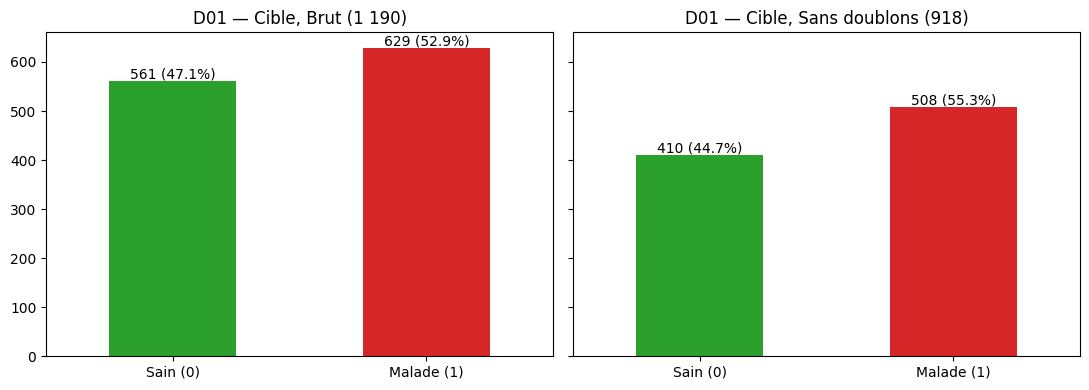

In [7]:
# ===== EDA D01 — Section 3 : Cible =====
cnt = y.value_counts().sort_index()
print("y :", cnt.to_dict(), "| proportions :", y.value_counts(normalize=True).round(3).sort_index().to_dict())
comp_art = pd.DataFrame({"Notre version (brut)": {"malades": int(cnt[1]), "sains": int(cnt[0])},
                         "Article":              {"malades": 629, "sains": 561},
                         "Sans doublons":        {"malades": int((sans_dup.target == 1).sum()), "sains": int((sans_dup.target == 0).sum())}})
display(comp_art); comp_art.to_csv("results/tables/D01_cible_vs_article.csv")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, d, t in [(a1, raw, "Brut (1 190)"), (a2, sans_dup, "Sans doublons (918)")]:
    v = d.target.value_counts().sort_index(); v.index = ["Sain (0)", "Malade (1)"]
    v.plot.bar(ax=ax, color=["#2ca02c", "#d62728"], rot=0); ax.set_title(f"D01 — Cible, {t}")
    for i, n in enumerate(v): ax.text(i, n + 5, f"{n} ({n/len(d):.1%})", ha="center")
plt.tight_layout(); plt.savefig("results/figures/D01_cible.png", dpi=120); plt.show()

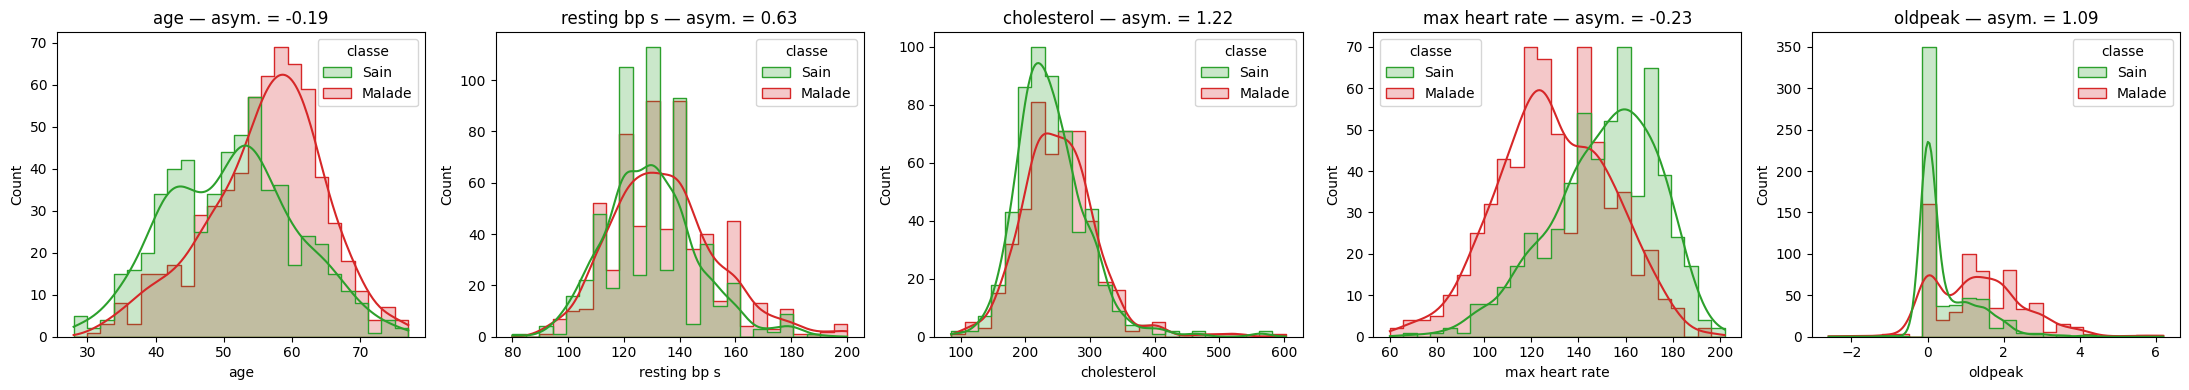

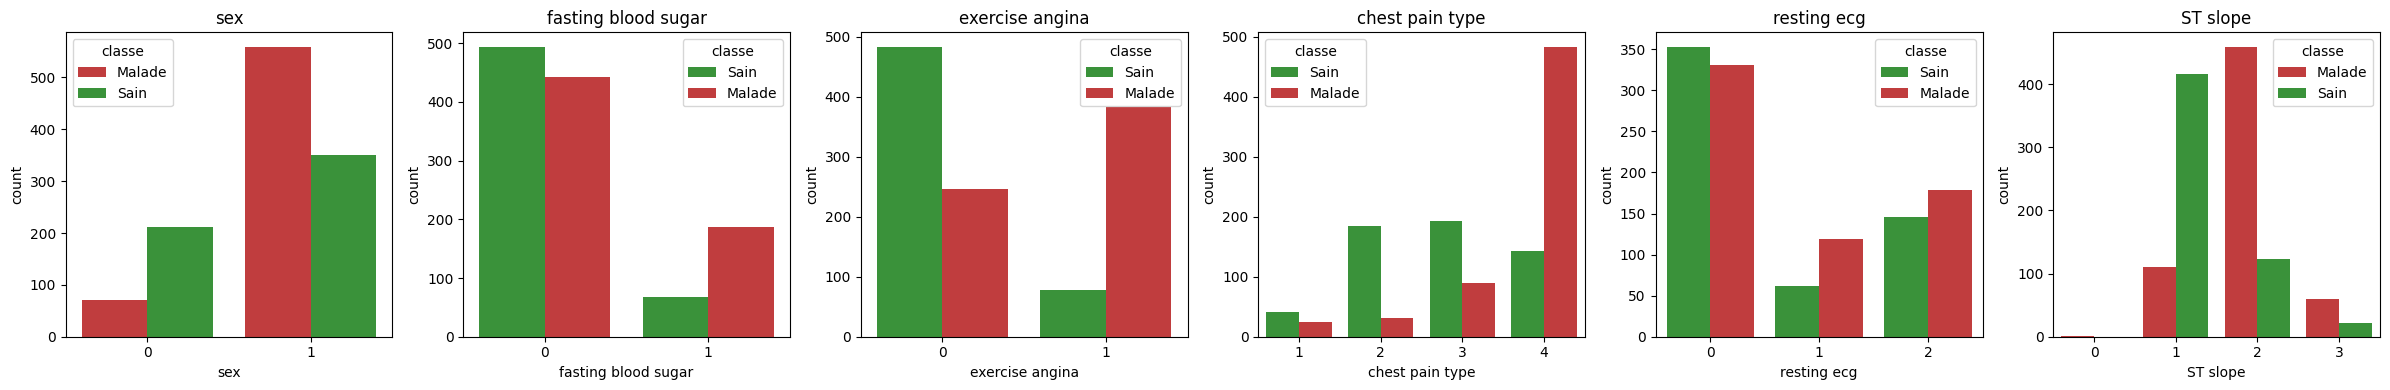

,count,mean,std,min,50%,max,asymétrie
age,1190.0,53.72,9.36,28.0,54.0,77.0,-0.19
resting bp s,1189.0,132.26,17.97,80.0,130.0,200.0,0.63
cholesterol,1018.0,245.91,57.24,85.0,240.0,603.0,1.22
max heart rate,1190.0,139.73,25.52,60.0,140.5,202.0,-0.23
oldpeak,1190.0,0.92,1.09,-2.6,0.6,6.2,1.09


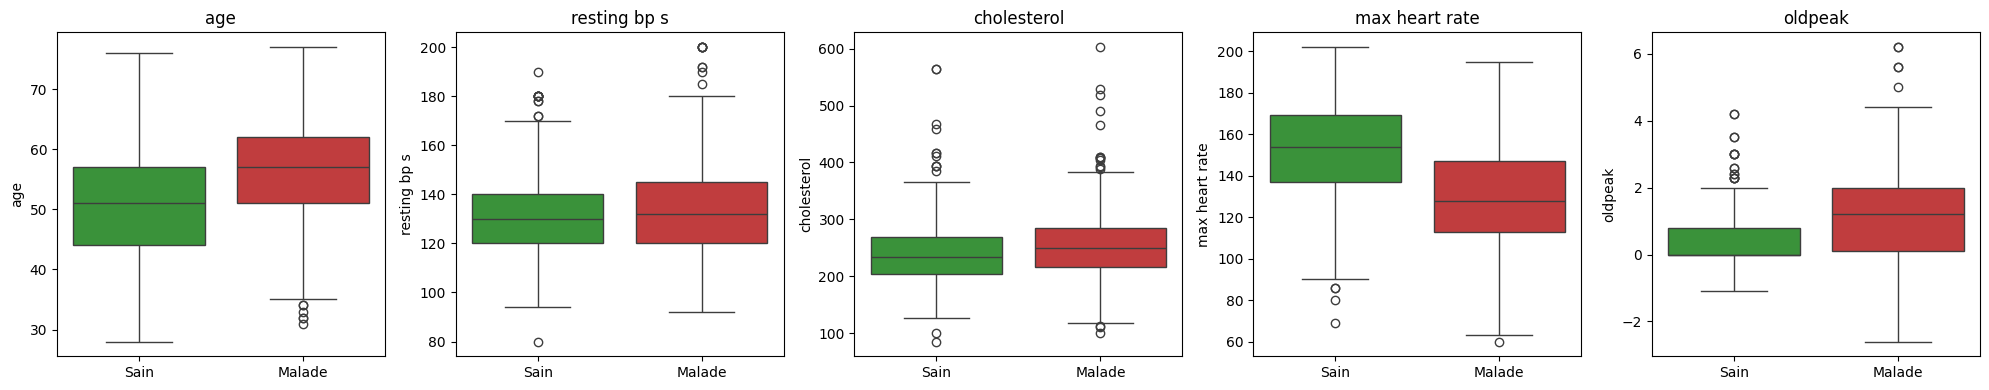

,borne_basse_IQR,borne_haute_IQR,nb_outliers_IQR,min_out,max_out,hors_bornes_médicales,oldpeak_négatifs
variable,,,,,,,
age,27.5,79.5,0,NaN,NaN,0,NaN
resting bp s,90.0,170.0,36,80.0,200.0,0,NaN
cholesterol,108.5,376.5,28,85.0,603.0,1,NaN
max heart rate,62.5,218.5,1,60.0,60.0,0,NaN
oldpeak,-2.4,4.0,11,-2.6,6.2,0,13.0


In [8]:
# ===== EDA D01 — Sections 4 et 5 : Distributions + valeurs aberrantes (zéros → NaN) =====
PAL = {"Sain": "#2ca02c", "Malade": "#d62728"}
df = X.copy()
for c in CAT: df[c] = pd.to_numeric(df[c])
df["classe"] = y.map({0: "Sain", 1: "Malade"})

# 4a. Numériques par classe
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, c in zip(axes, NUM):
    sns.histplot(data=df, x=c, hue="classe", kde=True, bins=25, palette=PAL, ax=ax, element="step")
    ax.set_title(f"{c} — asym. = {df[c].skew():.2f}")
plt.tight_layout(); plt.savefig("results/figures/D01_hist.png", dpi=120, bbox_inches="tight"); plt.show()

# 4b. Binaires et catégorielles par classe
fig, axes = plt.subplots(1, 6, figsize=(24, 4))
for ax, c in zip(axes, BIN + CAT):
    sns.countplot(data=df, x=c, hue="classe", palette=PAL, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.savefig("results/figures/D01_categorielles.png", dpi=120, bbox_inches="tight"); plt.show()

stats = df[NUM].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2)
stats["asymétrie"] = df[NUM].skew().round(2)
display(stats)

# 5. Boxplots + règle IQR + bornes médicales
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, NUM):
    sns.boxplot(data=df, x="classe", y=c, hue="classe", palette=PAL, ax=ax, legend=False, order=["Sain", "Malade"])
    ax.set_title(c); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("results/figures/D01_boxplots.png", dpi=120, bbox_inches="tight"); plt.show()

BORNES = {"age": (18, 100), "resting bp s": (70, 250), "cholesterol": (100, 700),
          "max heart rate": (60, 220), "oldpeak": (-3, 7)}
lignes = []
for c in NUM:
    s = df[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr; out = s[(s < bas) | (s > haut)]
    lo, hi = BORNES[c]
    lignes.append({"variable": c, "borne_basse_IQR": round(bas, 1), "borne_haute_IQR": round(haut, 1),
                   "nb_outliers_IQR": len(out), "min_out": out.min() if len(out) else None,
                   "max_out": out.max() if len(out) else None,
                   "hors_bornes_médicales": int(((s < lo) | (s > hi)).sum()),
                   "oldpeak_négatifs": int((s < 0).sum()) if c == "oldpeak" else None})
outliers = pd.DataFrame(lignes).set_index("variable")
display(outliers); outliers.to_csv("results/tables/D01_outliers.csv")

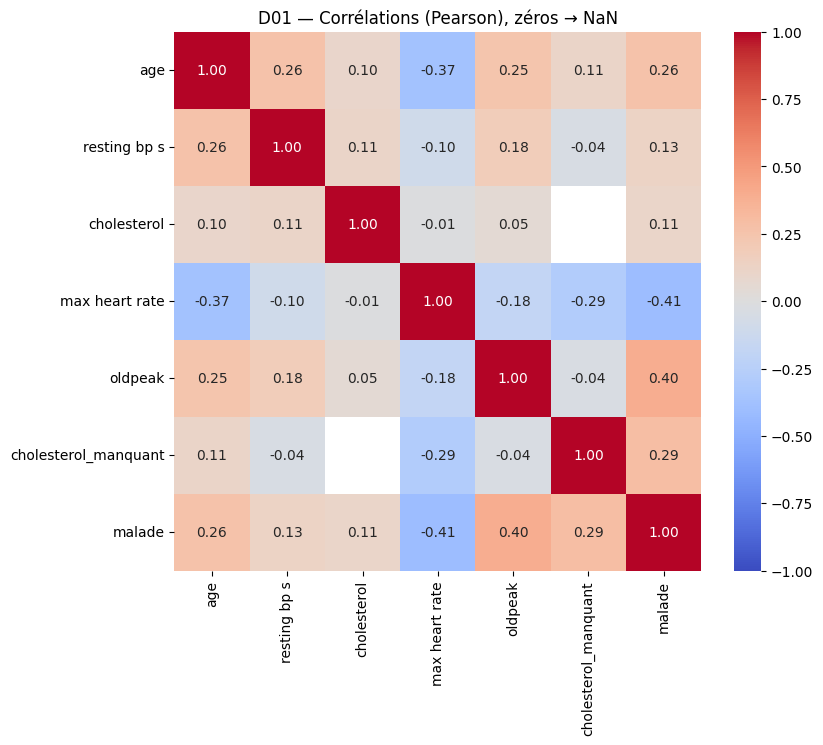

,type,test,p_value,effet,mesure_effet,AUC_seule,"significatif (p<0,05)"
variable,,,,,,,
ST slope,catégorielle,Chi²,1.3e-83,0.570,V de Cramér,NaN,True
chest pain type,catégorielle,Chi²,3.5e-72,0.530,V de Cramér,NaN,True
exercise angina,catégorielle,Chi²,1.6e-61,0.480,V de Cramér,NaN,True
max heart rate,numérique,Mann-Whitney,2.3e-47,-0.413,corrélation r,0.742,True
oldpeak,numérique,Mann-Whitney,8.7e-45,0.398,corrélation r,0.729,True
sex,catégorielle,Chi²,1.4e-26,0.309,V de Cramér,NaN,True
cholesterol_manquant,catégorielle,Chi²,1.4e-23,0.290,V de Cramér,NaN,True
age,numérique,Mann-Whitney,7.3e-21,0.262,corrélation r,0.657,True
fasting blood sugar,catégorielle,Chi²,1.3e-13,0.215,V de Cramér,NaN,True


In [9]:
# ===== EDA D01 — Section 6 : Corrélations + associations avec la maladie =====
from scipy.stats import mannwhitneyu, chi2_contingency
from sklearn.metrics import roc_auc_score

df["cholesterol_manquant"] = df["cholesterol"].isna().astype(int)

plt.figure(figsize=(8.5, 7))
sns.heatmap(df[NUM + ["cholesterol_manquant"]].assign(malade=y).corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("D01 — Corrélations (Pearson), zéros → NaN")
plt.savefig("results/figures/D01_corr.png", dpi=120, bbox_inches="tight"); plt.show()

lignes = []
for c in NUM:
    s = df[c]; m = s.notna(); auc = roc_auc_score(y[m], s[m])
    lignes.append({"variable": c, "type": "numérique", "test": "Mann-Whitney",
                   "p_value": mannwhitneyu(s[m & (y == 1)], s[m & (y == 0)]).pvalue,
                   "effet": round(s.corr(y), 3), "mesure_effet": "corrélation r", "AUC_seule": round(max(auc, 1 - auc), 3)})
for c in BIN + CAT + ["cholesterol_manquant"]:
    t = pd.crosstab(df[c], y); chi2, p, _, _ = chi2_contingency(t)
    lignes.append({"variable": c, "type": "catégorielle", "test": "Chi²", "p_value": p,
                   "effet": round(np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))), 3),
                   "mesure_effet": "V de Cramér", "AUC_seule": np.nan})
assoc = pd.DataFrame(lignes).set_index("variable")
assoc["significatif (p<0,05)"] = assoc["p_value"] < 0.05
assoc["p_value"] = assoc["p_value"].map(lambda p: f"{p:.1e}")
assoc = assoc.reindex(assoc["effet"].abs().sort_values(ascending=False).index)
display(assoc); assoc.to_csv("results/tables/D01_associations.csv")

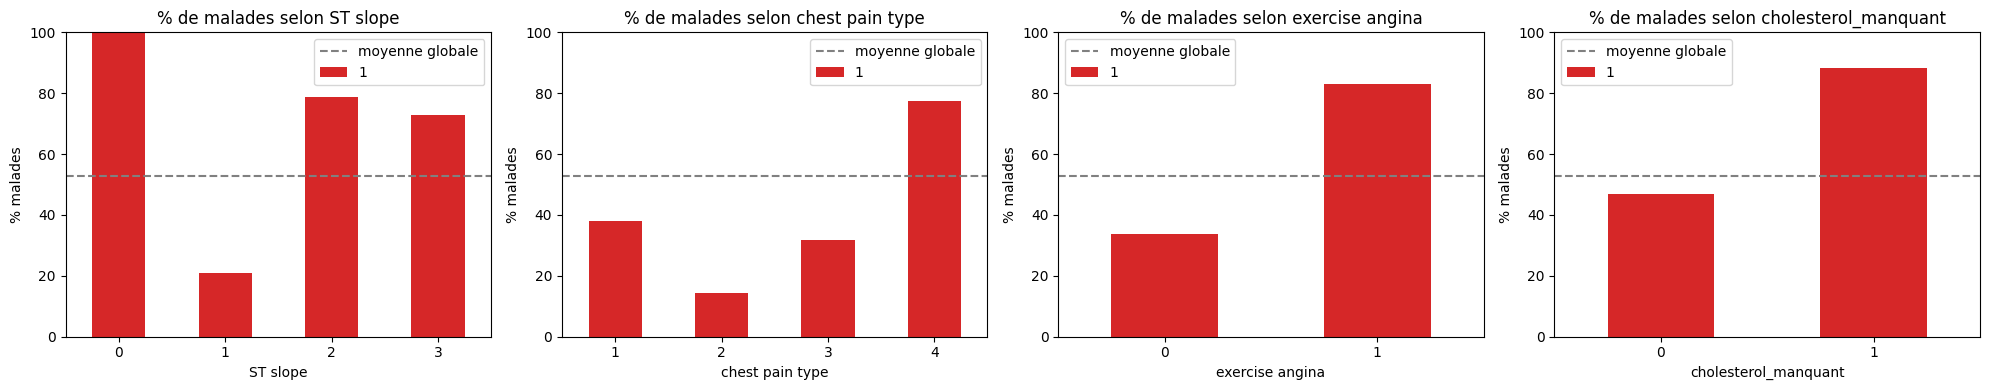

=== CONTRÔLE DE FUITE D01 ===
1. Cible absente de X : True
2. Colonne identifiant : aucune
3. Meilleure AUC d'une variable seule : 0.742 (max heart rate) → OK (< 0,95)
4. Cholestérol manquant : 172 patients, 88% de malades (contre 53%) → V de Cramér = 0.29
5. Validation croisée 10 folds sur les 1 190 lignes : 490 prédictions de test (41.2%) portent sur un patient dont la copie exacte est dans l'entraînement


In [10]:
# ===== EDA D01 — Section 7 : Lien avec la maladie + contrôle de fuite =====
from sklearn.model_selection import StratifiedKFold

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, ["ST slope", "chest pain type", "exercise angina", "cholesterol_manquant"]):
    (pd.crosstab(df[c], y, normalize="index")[1] * 100).plot.bar(ax=ax, color="#d62728", rot=0)
    ax.axhline(y.mean() * 100, ls="--", c="grey", label="moyenne globale"); ax.legend()
    ax.set_title(f"% de malades selon {c}"); ax.set_ylim(0, 100); ax.set_ylabel("% malades")
plt.tight_layout(); plt.savefig("results/figures/D01_lien_maladie.png", dpi=120, bbox_inches="tight"); plt.show()

print("=== CONTRÔLE DE FUITE D01 ===")
print("1. Cible absente de X :", "target" not in X.columns)
print("2. Colonne identifiant :", [c for c in X.columns if "id" in c.lower()] or "aucune")
max_auc = assoc["AUC_seule"].max()
print(f"3. Meilleure AUC d'une variable seule : {max_auc} ({assoc['AUC_seule'].idxmax()})",
      "→ OK (< 0,95)" if max_auc < 0.95 else "→ ⚠ SUSPECT")
print(f"4. Cholestérol manquant : {df.cholesterol_manquant.sum()} patients, "
      f"{y[df.cholesterol_manquant == 1].mean():.0%} de malades (contre {y.mean():.0%}) "
      f"→ V de Cramér = {assoc.loc['cholesterol_manquant', 'effet']}")

# 5. Doublons : combien de patients de test ont leur copie exacte dans l'entraînement ?
cle = raw.drop(columns="target").astype(str).agg("|".join, axis=1)
skf = StratifiedKFold(10, shuffle=True, random_state=42)
vus = sum(cle.iloc[te].isin(set(cle.iloc[tr])).sum() for tr, te in skf.split(raw, raw.target))
print(f"5. Validation croisée 10 folds sur les 1 190 lignes : {vus} prédictions de test ({vus/len(raw):.1%}) "
      f"portent sur un patient dont la copie exacte est dans l'entraînement")

In [11]:
# ===== Correction config D01 : ST slope = 0 -> valeur manquante =====
p = "src/datasets/m1.py"
s = open(p, encoding="utf-8").read()
old = 'zero_as_nan=["cholesterol", "resting bp s"],'
new = 'zero_as_nan=["cholesterol", "resting bp s", "ST slope"],  # ST slope=0 : code invalide (1 ligne)'
assert s.count(old) == 1, "Ligne introuvable : arrête-toi et envoie-moi le contenu de m1.py"
open(p, "w", encoding="utf-8").write(s.replace(old, new))

print("=== Modification (doit porter sur 1 seule ligne) ===")
!git diff src/datasets/m1.py

!git add src/datasets/m1.py
!git status --short
!git commit -q -m "m1 : D01 config, ST slope=0 traité comme manquant (EDA)"
!git push -q origin m1
!git log --oneline -2

=== Modification (doit porter sur 1 seule ligne) ===
diff --git a/src/datasets/m1.py b/src/datasets/m1.py
index 7337329..0119fc4 100644
--- a/src/datasets/m1.py
+++ b/src/datasets/m1.py
@@ -4,7 +4,7 @@ CONFIGS = {
                 file="d01_heart_comprehensive.csv",
                 source=("kaggle", "sid321axn/heart-statlog-cleveland-hungary-final", "heart_statlog_cleveland_hungary_final.csv"),
                 target="target", positive=1,                                   # 629 malades / 561 sains = article
-                zero_as_nan=["cholesterol", "resting bp s"],                   # 172 cholestérols à 0 (impossible)
+                zero_as_nan=["cholesterol", "resting bp s", "ST slope"],  # ST slope=0 : code invalide (1 ligne)                   # 172 cholestérols à 0 (impossible)
                 categorical=["chest pain type", "resting ecg", "ST slope"], verified=True),
     "D02": dict(name="Heart Disease UCI (Cleveland)", category="heart", owner="m1",
                 file="

In [4]:
# ===== Vérification après correction =====
from src.data import load_dataset, REGISTRY
X, y = load_dataset("D01")
print("zero_as_nan :", REGISTRY["D01"]["zero_as_nan"])
print("X :", X.shape, "| y :", y.value_counts().sort_index().to_dict())
print("Manquants après chargement :", X.isna().sum()[X.isna().sum() > 0].to_dict())
print("Modalités ST slope :", X["ST slope"].value_counts(dropna=False).to_dict())

zero_as_nan : ['cholesterol', 'resting bp s', 'ST slope']
X : (1190, 11) | y : {0: 561, 1: 629}
Manquants après chargement : {'resting bp s': 1, 'cholesterol': 172, 'ST slope': 1}
Modalités ST slope : {2.0: 582, 1.0: 526, 3.0: 81, nan: 1}


## Conclusions
(3 à 5 phrases avec des chiffres)

## Conclusions — EDA D01 (Heart Disease Comprehensive)

**Données.** 1 190 lignes, 11 variables (5 numériques, 3 binaires, 3 catégorielles), fusion de 5 bases (Cleveland, Hongrie, Suisse, Long Beach VA, Statlog). Cible : **629 malades (52,9 %) / 561 sains (47,1 %)**, identique à l'article (table 2) → classes équilibrées, validation croisée stratifiée.

**Doublons — problème majeur.** **272 lignes sont des copies exactes** d'autres lignes (544 lignes concernées, aucun conflit d'étiquette). 237 des 272 copies se trouvent dans les 270 dernières lignes : elles proviennent du bloc **Statlog, qui reprend des patients de Cleveland**. Sans doublons, il reste **918 patients (508 malades / 410 sains, 55,3 %)**. En validation croisée 10 folds sur les 1 190 lignes, **490 prédictions de test sur 1 190 (41,2 %) portent sur un patient dont la copie exacte est dans l'entraînement** : les scores sur D01 brut seront **optimistes**. Nous gardons la version brute pour la comparaison avec l'article et évaluons en plus une variante **sans doublons** (phase S2).

**Valeurs impossibles.** **172 cholestérols = 0** (14,5 %), 1 tension = 0 et 1 `ST slope` = 0 (code non documenté) → traités comme **valeurs manquantes** (`zero_as_nan`) puis imputés dans chaque fold (médiane / modalité la plus fréquente). Le cholestérol moyen passe de 210 à 245 mg/dl une fois les zéros retirés. Les autres valeurs extrêmes (tension 80–200 mm Hg, cholestérol jusqu'à 603 mg/dl, 13 `oldpeak` négatifs = sus-décalage ST) sont plausibles : **aucune ligne supprimée**.

**Biais de source.** Les cholestérols manquants ne sont pas aléatoires : **88 % de malades** parmi ces 172 patients (contre 53 % au global), V de Cramér = 0,29 (7ᵉ variable la plus liée à la maladie, devant l'âge). Ils proviennent de bases où le dosage n'était pas fait et où la majorité des patients étaient malades : un modèle peut apprendre **l'hôpital d'origine** plutôt que la physiologie. De même, `fasting blood sugar` est liée à la maladie dans D01 (V = 0,22) alors qu'elle ne l'est pas dans D02 (p = 0,78). Limite à garder en tête pour l'interprétation.

**Variables discriminantes.** `ST slope` (V = 0,57 ; environ 79 % de malades si pente plate contre 21 % si montante), `chest pain type` (V = 0,53 ; environ 77 % de malades chez les asymptomatiques), `exercise angina` (V = 0,48), `max heart rate` (r = −0,41) et `oldpeak` (r = 0,40) : mêmes signaux cliniques que D02.

**Contrôle de fuite.** Aucune variable seule ne dépasse une AUC de 0,742 (`max heart rate`), pas d'identifiant, corrélations entre variables ≤ 0,37. **La principale source d'optimisme est la présence des doublons**, pas une variable cachée.

**Traitements appliqués (`src/datasets/m1.py`).** `positive=1` ; `zero_as_nan = ["cholesterol", "resting bp s", "ST slope"]` ; `chest pain type`, `resting ecg`, `ST slope` en catégorielles (one-hot) ; imputation et standardisation **apprises dans chaque fold** (`src/common.py`).

In [6]:
# ===== SAUVEGARDE D01 — UNIQUEMENT mes fichiers, sur m1 =====
FICHIERS = ["results/figures/D01_*.png", "results/tables/D01_*.csv"]
MESSAGE = "S1 EDA D01 : figures et tableaux"

for f in FICHIERS:
    !git add "{f}"
print("=== Contenu du commit (vérifier : uniquement des fichiers D01_) ===")
!git status --short
!git commit -q -m "{MEMBRE} : {MESSAGE}" || echo "rien à sauvegarder"
!git pull -q --no-edit origin {MEMBRE} 2>/dev/null || true
!git push -q origin {MEMBRE}
!git branch --show-current
!git log --oneline -4

=== Contenu du commit (vérifier : uniquement des fichiers D01_) ===
A  results/figures/D01_boxplots.png
A  results/figures/D01_categorielles.png
A  results/figures/D01_cholesterol_avant_apres.png
A  results/figures/D01_cible.png
A  results/figures/D01_corr.png
A  results/figures/D01_hist.png
A  results/figures/D01_lien_maladie.png
A  results/tables/D01_apercu_variables.csv
A  results/tables/D01_associations.csv
A  results/tables/D01_cible_vs_article.csv
A  results/tables/D01_outliers.csv
A  results/tables/D01_qualite_avant_apres.csv
m1
fa3e031 (HEAD -> m1, origin/m1) m1 : S1 EDA D01 : figures et tableaux
a728acb m1 : D01 config, ST slope=0 traité comme manquant (EDA)
ea0fffd m1 : S1 EDA D02 : figures et tableaux
505ac4d (origin/main, origin/HEAD, main) Merge branch 'main' of https://github.com/eminealoui/ensemble-disease-prediction
